In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
import math
import random
import matplotlib.pyplot as plt

In [5]:
def visualize_tensor_reshape(shape, tensor):

    if len(shape)==0:
        return tensor

    if len(shape) == 1:
        return tensor
    
    else:
        first_dimension = shape[0]
        remaining_shape = shape[1:]
        chunk_size=1
        for i in remaining_shape:
            chunk_size*=i

        new_inner_tensor=[tensor[i:i+chunk_size] for i in range(0, len(tensor), chunk_size)]
        
        return [
    visualize_tensor_reshape(remaining_shape, chunk)
    for chunk in new_inner_tensor
]
        



class Tensor():
    def __init__(self, shape, data, parents=None, operation="", gradient_func=None):
        self.shape=shape
        self.data=data
        self.parents=parents
        self.operation=operation

        size = 1
        for d in shape:
            size *= d

        self.gradient = [0] * size
        self.gradient_func=gradient_func


    def __repr__(self):
        return f"(shape=({self.shape}), data=({visualize_tensor_reshape(self.shape, self.data)}), operation=({self.operation}), parents=({self.parents}), gradient=({self.gradient}))"


    def __add__(self, other):
        assert self.shape==other.shape

        out=[self_data+other_data for self_data, other_data in zip(self.data, other.data)]

        out_tensor=Tensor(self.shape, out,[self, other], "+")

        def backward_func():
            self.gradient=[self_gradient+(1*out_tensor_gradient) for self_gradient, out_tensor_gradient in zip(self.gradient, out_tensor.gradient)]
            other.gradient=[other_gradient+(1*out_tensor_gradient) for other_gradient, out_tensor_gradient in zip(other.gradient, out_tensor.gradient)]

        out_tensor.gradient_func=backward_func
                
        
        return out_tensor


    def __sub__(self, other):
        assert self.shape==other.shape

        out=[self_data-other_data for self_data, other_data in zip(self.data, other.data)]

        out_tensor=Tensor(self.shape, out, [self, other], "-")

        def backward_func():
            self.gradient=[self_gradient+(1*out_tensor_gradient) for self_gradient, out_tensor_gradient in zip(self.gradient, out_tensor.gradient)]
            other.gradient=[other_gradient+(-1*out_tensor_gradient) for other_gradient, out_tensor_gradient in zip(other.gradient, out_tensor.gradient)]

        out_tensor.gradient_func=backward_func
        
        return out_tensor

    def __mul__(self, other): #element wise multiplication

        if len(other.shape)==0:
            out=[self_data*other.data[0] for self_data in self.data]

        else:
            assert self.shape==other.shape
    
            out=[self_data*other_data for self_data, other_data in zip(self.data, other.data)]

        out_tensor=Tensor(self.shape, out, [self, other], "elemnt-wise *")

        def backward_func():
            self.gradient=[self_gradient+(other_data*out_tensor_gradient) for self_gradient, other_data, out_tensor_gradient in zip(self.gradient, other.data, out_tensor.gradient)]
            other.gradient=[other_gradient+(self_data*out_tensor_gradient) for self_data, other_gradient, out_tensor_gradient in zip(self.data, other.gradient, out_tensor.gradient)]

        out_tensor.gradient_func=backward_func
        
        return out_tensor


    def __pow__(self, constant):
        out=[self_data**constant for self_data in self.data]

        out_tensor=Tensor(self.shape, out, [self], "**")

        def backward_func():
            self.gradient=[self_gradient+((constant*(self_data**(constant-1)))*out_tensor_gradient) for self_gradient, self_data, out_tensor_gradient in zip(self.gradient, self.data, out_tensor.gradient)]
            
        out_tensor.gradient_func=backward_func
        
        return out_tensor

#FIX: //dot_product, //transpose, //matmul,  addrowwise
    
    def dot_product(self, other):
        assert self.shape==other.shape

        out=sum([self_data*other_data for self_data, other_data in zip(self.data, other.data)])

        out_tensor=Tensor([], out, [self, other], "dot-product")

        def backward_func():
            self.gradient=[self_gradient+(other_data*out_tensor.gradient[0]) for self_gradient, other_data in zip(self.gradient, other.data)]
            other.gradient=[other_gradient+(self_data*out_tensor.gradient[0]) for other_gradient, self_data in zip(other.gradient, self.data)]

        out_tensor.gradient_func=backward_func
        
        return out_tensor




    def transpose(self): #2D without being generalized yet
        
        rows, cols = self.shape
        
        new_data = [0] * len(self.data)
        
        for i in range(rows):
            for j in range(cols):
                old = i * cols + j
                new = j * rows + i
                new_data[new] = self.data[old]

        out_tensor=Tensor([cols, rows], new_data, [self], "transpose")

        def backward_func():

            out_tensor_gradient_tensor=Tensor(shape=out_tensor.shape, data=out_tensor.gradient)
            out_tensor_gradient_tensor_transpose=out_tensor_gradient_tensor.transpose()
            self.gradient=[self_gradient+(out_tensor_gradient_tensor_transpose_data) for self_gradient, out_tensor_gradient_tensor_transpose_data in zip (self.gradient, out_tensor_gradient_tensor_transpose.data)]

        out_tensor.gradient_func=backward_func
        
        return out_tensor



    def __matmul__(self, other):
    
        assert self.shape[1]==other.shape[0]

        new_shape=[self.shape[0], other.shape[1]]

        new_data=[]

        for i in range(self.shape[0]):

            row_i=self.data[i*self.shape[1]:i*self.shape[1]+self.shape[1]]
            
            #print(row_i)

            for j in range(other.shape[1]):

                col_j=[]

                for z in range(other.shape[0]):
                    col_j.append(other.data[z*other.shape[1]+j])
                #row*n columns+column
                

                #print(col_j)

                #print(f"PAIRS: row:{row_i}, col:{col_j}")
                
                #print(f"i:{i}, j:{j}")

                row_tensor=Tensor([1,self.shape[0]], row_i)
                col_tensor=Tensor([1,self.shape[0]], col_j)

                
                #print(row_tensor)
                #print(col_tensor)

                dot_prod=row_tensor.dot_product(col_tensor)
                #print(dot_prod)

                new_data.append(dot_prod.data)

        out_tensor=Tensor(new_shape, new_data, [self, other], "matmul")

        def backward_func():


            out_tensor_gradient_tensor=Tensor(out_tensor.shape, out_tensor.gradient)
            #print("out gradient: ",out_tensor_gradient_tensor)

            self_transpose=self.transpose()
            other_transpose=other.transpose()

            #print("self transpose: ",self_transpose)    
            #print("other transpose: ",other_transpose)

            self_gradient_tensor=out_tensor_gradient_tensor@other_transpose
            other_gradient_tensor=self_transpose@out_tensor_gradient_tensor

            #print("SHAPE SELF GRADIENT: ",self_gradient_tensor.data)
            #print("SHAPE OTHER GRADIENT: ",other_gradient_tensor.data)
            
            self.gradient=self_gradient_tensor.data
            other.gradient=other_gradient_tensor.data
            
        out_tensor.gradient_func=backward_func
        
        return out_tensor

    def column_wise_addition(self, other):
        '''
        for each column in the matrix, add the element b 
        Z=(m,j)
        b=(j,1)

        for each column z_j, add the element b_j to that column
        
        '''

        self_columns=[]
        

        for i in range(self.shape[1]):
            
            column=[]
            
            for j in range(self.shape[0]):
                

                column.append(self.data[j*self.shape[1]+i])
            self_columns.append(column)

        new_columns=[[self_col_j+other_j for self_col_j in self_column] for self_column, other_j in zip(self_columns, other.data)]
        
        #print(self_columns)
        #print("New")
        #print(new_columns)
        
        #print("HI")

        reconstructed=[]

        for i in range(len(new_columns[0])):
            for j in range(len(new_columns)):

                reconstructed.append(new_columns[j][i])
        #print(reconstructed)

        out_tensor=Tensor(self.shape, reconstructed, [self,other], "column-wise addition")

        def backward_func():

            m, n = self.shape

            
            #self.gradient: Don't trust this since its chatgpt code
            for i in range(m * n):
                self.gradient[i] += out_tensor.gradient[i]

            #other.gradient: Don't trust this since its chatgpt code
            for j in range(n):
                grad = 0
                for i in range(m):
                    grad += out_tensor.gradient[i * n + j]
                other.gradient[j] += grad
            
        
        out_tensor.gradient_func=backward_func 
        
        return out_tensor





    def softmax_rows(self): #CHATGPT CODE
        m, n = self.shape
    
        out = [0] * (m * n)
    
        for i in range(m):
            row_start = i * n
            row_end = (i + 1) * n
    
            row = self.data[row_start:row_end]
    
            # stability trick (VERY important even in toy engines)
            max_val = max(row)
            exps = [math.exp(x - max_val) for x in row]
    
            denom = sum(exps)
    
            for j in range(n):
                out[row_start + j] = exps[j] / denom
    
        out_tensor = Tensor(self.shape, out, [self], "softmax_rows")

        def backward_func():
            m, n = self.shape
    
            for i in range(m):
                row_start = i * n
                row_end = (i + 1) * n
    
                s = out_tensor.data[row_start:row_end]
                g = out_tensor.gradient[row_start:row_end]
    
                dot = sum(g[j] * s[j] for j in range(n))
    
                for j in range(n):
                    self.gradient[row_start + j] += s[j] * (g[j] - dot)

        out_tensor.gradient_func = backward_func
        return out_tensor
        
    
    def exp(self):

        out=[math.exp(self_data) for self_data in self.data]

        out_tensor=Tensor(self.shape, out, [self], "exp")

        def backward_func():
            self.gradient=[self_gradient+((out_data)*out_tensor_gradient) for self_gradient, out_data, out_tensor_gradient in zip(self.gradient, out_tensor.data, out_tensor.gradient)]
            
        out_tensor.gradient_func=backward_func      
        
        return out_tensor

    def sum(self):
        resulting=sum(self.data)

        out_tensor=Tensor([], [resulting], [self], "sum of inner items")

        def backward_func():
            self.gradient=[self_gradient+(1*out_tensor.gradient[0]) for self_gradient in self.gradient]
        out_tensor.gradient_func=backward_func 

        return out_tensor


    def backward(self):
        topo=[] 
        visited=set() 
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                if v.parents is not None:
                    for child in v.parents:
                        build_topo(child)
                    topo.append(v)
        build_topo(self)

        self.gradient=[1 for self_gradient in self.gradient]
        for node in reversed(topo):
            if node.gradient_func!=None:
                node.gradient_func()

    


#add thing where if I access a value from the data of a tensor, create a tensor with that value


In [6]:
def kernel_initializer_he_normal(size, fan_in):
    std = math.sqrt(2.0 / fan_in)
    return [random.gauss(0, std) for _ in range(size)]

def kernel_initializer_zeros(size):
    return [0.0] * size

def causal_mask(seq_len):
    mask = []

    for i in range(seq_len):
        for j in range(seq_len):
            if j <= i:
                mask.append(0)
            else:
                mask.append(float("-inf"))

    return Tensor([seq_len, seq_len], mask)

class Dense():
    def __init__(self, n_inputs, n_outputs):
        self.n_inputs=n_inputs
        self.n_outputs=n_outputs
        self.W=Tensor([n_inputs, n_outputs], kernel_initializer_he_normal(n_inputs*n_outputs, (n_inputs)))
        self.b=Tensor([n_outputs,1], kernel_initializer_zeros(n_outputs))
        #missing activation, kernel constraints and kernel regularizer

    def __call__(self, X):
        z=(X@self.W).column_wise_addition(self.b)
        return z

class ScaledDotProductAttention():
    def __init__(self, n_dimensions_used, token_n_dimensions):
        self.n_dimensions_used=n_dimensions_used
        self.token_n_dimensions=token_n_dimensions

        self.Wq=Tensor([token_n_dimensions, n_dimensions_used], kernel_initializer_he_normal(token_n_dimensions*n_dimensions_used, (token_n_dimensions)))
        self.Wk=Tensor([token_n_dimensions, n_dimensions_used], kernel_initializer_he_normal(token_n_dimensions*n_dimensions_used, (token_n_dimensions)))
        self.Wv=Tensor([token_n_dimensions, n_dimensions_used], kernel_initializer_he_normal(token_n_dimensions*n_dimensions_used, (token_n_dimensions)))

    def __call__(self, X):
        Q=(X@self.Wq)
        K=(X@self.Wk)
        V=(X@self.Wv)

        K_transpose=K.transpose()
        
        simmilarity_scores=Q@K_transpose

        #scaling_factor=Tensor([], [1/(self.n_dimensions_used**(1/2))])

        #since the scaling factor breaks, I will make a matrix the same shape and fill it with scaled factor

        scaling_factor_matrix=[1/(self.n_dimensions_used**(1/2)) for i in range(simmilarity_scores.shape[0]*simmilarity_scores.shape[1])]
        
        scaling_factor_matrix_tensor=Tensor(simmilarity_scores.shape, scaling_factor_matrix)
        
        scaled_simmilarity_scores=simmilarity_scores*scaling_factor_matrix_tensor

        scaled_simmilarity_scores_softmax=scaled_simmilarity_scores.softmax_rows()
        
        scaled_simmilarity_scores_softmax_V=scaled_simmilarity_scores_softmax@V
        
        return scaled_simmilarity_scores_softmax_V

class MaskedScaledDotProductAttention():
    def __init__(self, n_dimensions_used, token_n_dimensions):
        self.n_dimensions_used=n_dimensions_used
        self.token_n_dimensions=token_n_dimensions

        self.Wq=Tensor([token_n_dimensions, n_dimensions_used], kernel_initializer_he_normal(token_n_dimensions*n_dimensions_used, (token_n_dimensions)))
        self.Wk=Tensor([token_n_dimensions, n_dimensions_used], kernel_initializer_he_normal(token_n_dimensions*n_dimensions_used, (token_n_dimensions)))
        self.Wv=Tensor([token_n_dimensions, n_dimensions_used], kernel_initializer_he_normal(token_n_dimensions*n_dimensions_used, (token_n_dimensions)))
    
    def __call__(self, X):
        Q=(X@self.Wq)
        K=(X@self.Wk)
        V=(X@self.Wv)

        K_transpose=K.transpose()
        
        simmilarity_scores=Q@K_transpose

        #scaling_factor=Tensor([], [1/(self.n_dimensions_used**(1/2))])

        #since the scaling factor breaks, I will make a matrix the same shape and fill it with scaled factor

        scaling_factor_matrix=[1/(self.n_dimensions_used**(1/2)) for i in range(simmilarity_scores.shape[0]*simmilarity_scores.shape[1])]
        
        scaling_factor_matrix_tensor=Tensor(simmilarity_scores.shape, scaling_factor_matrix)
        
        scaled_simmilarity_scores=simmilarity_scores*scaling_factor_matrix_tensor

        casual_mask_matrix=causal_mask(X.shape[0])


        masked_scaled_simmilarity_scores=scaled_simmilarity_scores+casual_mask_matrix
        
        scaled_simmilarity_scores_softmax=masked_scaled_simmilarity_scores.softmax_rows()
        
        scaled_simmilarity_scores_softmax_V=scaled_simmilarity_scores_softmax@V
        
        return scaled_simmilarity_scores_softmax_V

class Concatenate():
    def __init__(self):
        pass

    def __call__(self, list_tensors):

        column_sizes = [tensor.shape[1] for tensor in list_tensors]
        
        total_columns=[]
        
        total_rows_counter=list_tensors[0].shape[0]
        
        for tensor in list_tensors:
            #print(tensor)

            tensor_columns=[]
            
            for j in range(tensor.shape[1]):

                column=[]
                
                for i in range(tensor.shape[0]):

                    column.append(tensor.data[i*tensor.shape[1]+j])
                tensor_columns.append(column)

            #print(tensor_columns)

            for c in tensor_columns:

                #for item in c:
                #    total_columns.append(item)
                total_columns.append(c)
        
        total_columns_counter=len(total_columns)
        
        reconstructed=[]

        for i in range(len(total_columns[0])):
            for j in range(len(total_columns)):

                reconstructed.append(total_columns[j][i])

        out_tensor=Tensor([total_rows_counter,total_columns_counter], reconstructed, list_tensors, "concat_layer")

        def backward_func():

            offset = 0
        
            for tensor in list_tensors:
        
                cols = tensor.shape[1]
        
                for j in range(cols):
        
                    out_col = offset + j
        
                    for i in range(tensor.shape[0]):
        
                        out_index = i * total_columns_counter + out_col
                        tensor_index = i * cols + j
        
                        tensor.gradient[tensor_index] += out_tensor.gradient[out_index]
        
                offset += cols

            
            
        out_tensor.gradient_func=backward_func 
        
        return out_tensor

class SplitRows(): #CHATGPT CODE
    def __call__(self, X):

        
        
        #print("SplitRows")
        #print("X.shape =", X.shape)
        #print("len(X.data) =", len(X.data))
        #print("len(X.gradient) =", len(X.gradient))
        
        rows, cols = X.shape
        out = []

        assert len(X.data) == rows * cols
        assert len(X.gradient) == rows * cols
        
        for row_idx in range(rows):

            row_data = X.data[row_idx*cols:(row_idx+1)*cols]

            out_tensor = Tensor([1, cols], row_data, [X], "split_row")

            def backward_func(out_tensor=out_tensor, row_idx=row_idx):
                #print("BACKWARD split_row")
                #print("row_idx =", row_idx)
                #print("cols =", cols)
                #print("len(X.gradient) =", len(X.gradient))
                #print("len(out_tensor.gradient) =", len(out_tensor.gradient))
            
                for i in range(cols):
                    if i >= len(out_tensor.gradient):
                        #print("out_tensor too short!", i)
                        break
            
                    idx = row_idx * cols + i
            
                    if idx >= len(X.gradient):
                        #print("X.gradient too short!", idx)
                        break
            
                    X.gradient[idx] += out_tensor.gradient[i]

            out_tensor.gradient_func = backward_func

            out.append(out_tensor)

            #print("row", row_idx)
            #print("len(row_data) =", len(row_data))
            #print("len(out_tensor.gradient) =", len(out_tensor.gradient))

        return out

    

class StackRows(): #CHATGPT CODE
    def __call__(self, list_tensors):

        rows = len(list_tensors)
        cols = list_tensors[0].shape[1]

        data = []

        for t in list_tensors:
            data.extend(t.data)

        out = Tensor([rows, cols], data, list_tensors, "stack_rows")

        def backward_func():
            offset = 0
            for t in list_tensors:
                for i in range(len(t.data)):
                    t.gradient[i] += out.gradient[offset + i]
                offset += len(t.data)

        out.gradient_func = backward_func
        return out

'''class LayerNormalization():
    def __init__(self, n_tokens, n_dimensions): 
        self.split_rows_layer=SplitRows()
        self.stack_rows_layer=StackRows()

        gamma_matrix=[0]*(n_tokens*n_dimensions)
        
        self.gamma=Tensor([n_tokens, n_dimensions], gamma_matrix)
        self.beta=Tensor([n_tokens, n_dimensions], gamma_matrix)
        

    def __call__(self,X): #[each row is a tensor]

        X_rows=self.split_rows_layer(X)
        
        
        normalized_rows=[]
        for row in X_rows:
            
            sum_row=row.sum()
            avg_term=Tensor([], [1/(row.shape[1])])
            mean=sum_row*avg_term

            mean_matrix_data=[mean.data[0] for _ in range(row.shape[1])]
            
            mean_matrix=Tensor(row.shape, mean_matrix_data)

            
            scaled_row=row-mean_matrix #tested until here
            
            squared_row=scaled_row**2

            added_squared_row=squared_row.sum()
            avg_term_2=Tensor([], [1/(row.shape[1])])

            variance_squared=added_squared_row*avg_term_2
            epsilon=Tensor([], [0.00001])

            variance_squared_epsilon_added=variance_squared+epsilon
            standard_deviation=variance_squared_epsilon_added**(0.5)

            standard_deviation_term=standard_deviation**(-1)

            row_normalized=scaled_row*standard_deviation_term
            
            normalized_rows.append(row_normalized)

        X_restored=self.stack_rows_layer(normalized_rows)

        
        result=(X_restored*self.gamma)+self.beta
        
        return result'''

class LayerNormalizationNew():
    def __init__(self, n_dimensions):
        self.split_rows_layer = SplitRows()
        self.stack_rows_layer = StackRows()

        gamma_matrix = [1] * n_dimensions
        beta_matrix  = [0] * n_dimensions

        self.gamma = Tensor([1, n_dimensions], gamma_matrix)
        self.beta  = Tensor([1, n_dimensions], beta_matrix)

    def __call__(self, X):

        X_rows = self.split_rows_layer(X)

        gamma_row = self.split_rows_layer(self.gamma)[0]
        beta_row  = self.split_rows_layer(self.beta)[0]

        normalized_rows = []

        for row in X_rows:

            mean = row.sum() * Tensor([], [1 / row.shape[1]])

            mean_matrix = Tensor(
                row.shape,
                [mean.data[0]] * row.shape[1]
            )

            centered = row - mean_matrix

            variance = (centered ** 2).sum() * Tensor([], [1 / row.shape[1]])

            std = (variance + Tensor([], [1e-5])) ** 0.5

            normalized = centered * (std ** (-1))

            # Same gamma and beta are applied to every row
            output_row = normalized * gamma_row + beta_row

            normalized_rows.append(output_row)

        return self.stack_rows_layer(normalized_rows)

class MultiHeadAttention():

    def __init__(self, n_heads, token_n_dimensions):
        self.n_heads=n_heads
        self.token_n_dimensions=token_n_dimensions
        self.n_dimensions_used_per_head=int(token_n_dimensions/n_heads)

        self.scaled_dot_product_attention_layers=[ScaledDotProductAttention(self.n_dimensions_used_per_head, token_n_dimensions) for i in range(n_heads)]

        self.concatenate_layer=Concatenate()

        self.Wo=Tensor([token_n_dimensions, token_n_dimensions], kernel_initializer_he_normal(token_n_dimensions*token_n_dimensions, (token_n_dimensions)))
    
    def __call__(self, X):
        result_tensors=[]

        for layer in self.scaled_dot_product_attention_layers:
            result_tensor=layer(X)
            result_tensors.append(result_tensor)

        concatenated_result=self.concatenate_layer(result_tensors)

        final_result=concatenated_result@self.Wo
        
        return final_result


class MaskedMultiHeadAttention():

    def __init__(self, n_heads, token_n_dimensions):
        self.n_heads=n_heads
        self.token_n_dimensions=token_n_dimensions
        self.n_dimensions_used_per_head=int(token_n_dimensions/n_heads)

        self.scaled_dot_product_attention_layers=[MaskedScaledDotProductAttention(self.n_dimensions_used_per_head, token_n_dimensions) for i in range(n_heads)]

        self.concatenate_layer=Concatenate()

        self.Wo=Tensor([token_n_dimensions, token_n_dimensions], kernel_initializer_he_normal(token_n_dimensions*token_n_dimensions, (token_n_dimensions)))
    
    def __call__(self, X):
        result_tensors=[]

        for layer in self.scaled_dot_product_attention_layers:
            result_tensor=layer(X)
            result_tensors.append(result_tensor)

        concatenated_result=self.concatenate_layer(result_tensors)

        final_result=concatenated_result@self.Wo
        
        return final_result
        
        


        

In [7]:
#DENSE MODEL 
class Model():
    def __init__(self):
        self.layers=[]

    def get_weights(self):
        weights=[]
        for layer in self.layers:
            weights.append(layer.W)
            weights.append(layer.b)
        return weights
    
    def add_layer(self, layer):
        self.layers.append(layer)
    
    def __call__(self, X):
        out=X
        for layer in self.layers:
            out=layer(out)
        return out

    def fit(self, X_train, y_train, epochs, learning_rate):

        history=[]
        
        for epoch in range(epochs):
            
            weights=self.get_weights()

            #set all weight gradients to zero. I think its not working well
            for w in weights:
                for i in range(len(w.gradient)):
                    w.gradient[i]=0

            
                    
            
            ypred=self(X_train)
            loss=(ypred-y_train)
            squared_loss=loss**2
            avg_term=Tensor([], [1/len(squared_loss.data)])
            sum_loss=squared_loss.sum()
            avg_loss=sum_loss*avg_term

            avg_loss.backward()

            #print(self.layers[0].W.data[:1])
            
            print(avg_loss.data)
            
            #for w in self.get_weights():
            #    print(max(abs(g) for g in w.gradient))

            weights=self.get_weights()
            
            for i in range(len(weights)):
                weights[i].data=[w_data-(learning_rate*w_gradient) for w_data, w_gradient in zip(weights[i].data, weights[i].gradient)]

            
            history.append(avg_loss.data)

        return history
    

In [8]:
text='''alice likes cats
alice likes dogs
alice likes birds
alice hates spiders
alice eats apples
alice eats pizza
bob likes dogs
bob likes pizza
bob hates cats
bob eats burgers
bob eats apples
charlie likes birds
charlie likes fish
charlie hates spiders
charlie eats pizza
charlie eats fish
david likes cars
david likes dogs
david hates birds
david eats burgers
david eats apples
emma likes cats
emma likes flowers
emma hates spiders
emma eats pizza
emma eats apples
frank likes cars
frank likes pizza
frank hates fish
frank eats burgers
grace likes birds
grace likes flowers
grace hates dogs
grace eats apples
henry likes cars
henry likes cats
henry hates spiders
henry eats pizza
isabella likes flowers
isabella likes birds
isabella hates fish
isabella eats apples
jack likes dogs
jack likes cars
jack hates cats
jack eats burgers'''


In [9]:
training_samples=text.split("\n")
new_training_samples=[]
final_training_samples=[]

words=[]
words_dict=[]

for sample in training_samples:
    new_sample=sample
    new_sample+=" <EOS>"
    new_training_samples.append(new_sample)

    new_sample_words=[]

    for word in new_sample.split(" "):
        if word not in words:
            words.append(word)
    
    

In [10]:
new_training_samples

['alice likes cats <EOS>',
 'alice likes dogs <EOS>',
 'alice likes birds <EOS>',
 'alice hates spiders <EOS>',
 'alice eats apples <EOS>',
 'alice eats pizza <EOS>',
 'bob likes dogs <EOS>',
 'bob likes pizza <EOS>',
 'bob hates cats <EOS>',
 'bob eats burgers <EOS>',
 'bob eats apples <EOS>',
 'charlie likes birds <EOS>',
 'charlie likes fish <EOS>',
 'charlie hates spiders <EOS>',
 'charlie eats pizza <EOS>',
 'charlie eats fish <EOS>',
 'david likes cars <EOS>',
 'david likes dogs <EOS>',
 'david hates birds <EOS>',
 'david eats burgers <EOS>',
 'david eats apples <EOS>',
 'emma likes cats <EOS>',
 'emma likes flowers <EOS>',
 'emma hates spiders <EOS>',
 'emma eats pizza <EOS>',
 'emma eats apples <EOS>',
 'frank likes cars <EOS>',
 'frank likes pizza <EOS>',
 'frank hates fish <EOS>',
 'frank eats burgers <EOS>',
 'grace likes birds <EOS>',
 'grace likes flowers <EOS>',
 'grace hates dogs <EOS>',
 'grace eats apples <EOS>',
 'henry likes cars <EOS>',
 'henry likes cats <EOS>',
 '

In [11]:
X_train = []
Y_train = []

for sentence in new_training_samples:
    tokens = sentence.split()

    # Input: everything except the last token
    X_train.append(tokens[:-1])

    # Target: everything except the first token
    Y_train.append(tokens[1:])

for x, y in zip(X_train[:10], Y_train[:10]):
    print("Input :", x)
    print("Target:", y)
    print()

Input : ['alice', 'likes', 'cats']
Target: ['likes', 'cats', '<EOS>']

Input : ['alice', 'likes', 'dogs']
Target: ['likes', 'dogs', '<EOS>']

Input : ['alice', 'likes', 'birds']
Target: ['likes', 'birds', '<EOS>']

Input : ['alice', 'hates', 'spiders']
Target: ['hates', 'spiders', '<EOS>']

Input : ['alice', 'eats', 'apples']
Target: ['eats', 'apples', '<EOS>']

Input : ['alice', 'eats', 'pizza']
Target: ['eats', 'pizza', '<EOS>']

Input : ['bob', 'likes', 'dogs']
Target: ['likes', 'dogs', '<EOS>']

Input : ['bob', 'likes', 'pizza']
Target: ['likes', 'pizza', '<EOS>']

Input : ['bob', 'hates', 'cats']
Target: ['hates', 'cats', '<EOS>']

Input : ['bob', 'eats', 'burgers']
Target: ['eats', 'burgers', '<EOS>']



In [12]:
words

['alice',
 'likes',
 'cats',
 '<EOS>',
 'dogs',
 'birds',
 'hates',
 'spiders',
 'eats',
 'apples',
 'pizza',
 'bob',
 'burgers',
 'charlie',
 'fish',
 'david',
 'cars',
 'emma',
 'flowers',
 'frank',
 'grace',
 'henry',
 'isabella',
 'jack']

In [13]:
for i, word in enumerate(words):
    words_dict.append({"index":i, "word":word})
words_dict

[{'index': 0, 'word': 'alice'},
 {'index': 1, 'word': 'likes'},
 {'index': 2, 'word': 'cats'},
 {'index': 3, 'word': '<EOS>'},
 {'index': 4, 'word': 'dogs'},
 {'index': 5, 'word': 'birds'},
 {'index': 6, 'word': 'hates'},
 {'index': 7, 'word': 'spiders'},
 {'index': 8, 'word': 'eats'},
 {'index': 9, 'word': 'apples'},
 {'index': 10, 'word': 'pizza'},
 {'index': 11, 'word': 'bob'},
 {'index': 12, 'word': 'burgers'},
 {'index': 13, 'word': 'charlie'},
 {'index': 14, 'word': 'fish'},
 {'index': 15, 'word': 'david'},
 {'index': 16, 'word': 'cars'},
 {'index': 17, 'word': 'emma'},
 {'index': 18, 'word': 'flowers'},
 {'index': 19, 'word': 'frank'},
 {'index': 20, 'word': 'grace'},
 {'index': 21, 'word': 'henry'},
 {'index': 22, 'word': 'isabella'},
 {'index': 23, 'word': 'jack'}]

In [14]:
def lookup(word):
    for item in words_dict:
        if item["word"]==word:
            
            return item["index"]
    return -1
            

In [15]:
class TokenEmbeddingLayer():
    def __init__(self, vocab_size, n_dimensions):
        self.vocab_size=vocab_size
        self.n_dimensions=n_dimensions
        self.embedding_matrix=Tensor([vocab_size, n_dimensions], kernel_initializer_he_normal(vocab_size*n_dimensions, vocab_size))

        self.split_rows_layer=SplitRows()
        self.stack_rows_layer=StackRows()
    
    def __call__(self, sequence):
        embedding_matrix_row_tensors=self.split_rows_layer(self.embedding_matrix)

        token_vectors=[]
        
        for token in sequence:
            token_index=lookup(token)
            token_vectors.append(embedding_matrix_row_tensors[token_index])
        
        out_tensor=self.stack_rows_layer(token_vectors)
        
        return out_tensor


class PositionalEncodingLayer():
    def __init__(self, max_sequence_length, n_dimensions):
        self.max_sequence_length=max_sequence_length
        self.n_dimensions=n_dimensions
        self.embedding_matrix=Tensor([max_sequence_length, n_dimensions], kernel_initializer_he_normal(max_sequence_length*n_dimensions, max_sequence_length))

        self.split_rows_layer=SplitRows()
        self.stack_rows_layer=StackRows()
    
    def __call__(self, sequence):
        embedding_matrix_row_tensors=self.split_rows_layer(self.embedding_matrix)

        token_vectors=embedding_matrix_row_tensors[:len(sequence)]
        
        
        out_tensor=self.stack_rows_layer(token_vectors)
        
        return out_tensor
        


In [16]:
len(words_dict)

24

In [17]:
class SoftmaxCrossEntropyLoss():

    def __call__(self, logits, targets):

        rows, cols = logits.shape

        losses = []

        for row in range(rows):

            # ----- Log-Sum-Exp -----

            row_logits = logits.data[row*cols:(row+1)*cols]

            max_logit = max(row_logits)

            exp_values = [math.exp(x - max_logit) for x in row_logits]

            sum_exp = sum(exp_values)

            log_sum_exp = max_logit + math.log(sum_exp)

            correct = targets[row]

            loss_value = -row_logits[correct] + log_sum_exp

            losses.append(loss_value)

        mean_loss = sum(losses) / rows

        out = Tensor([], [mean_loss], [logits], "cross_entropy")

        def backward_func():

            for row in range(rows):

                row_logits = logits.data[row*cols:(row+1)*cols]

                max_logit = max(row_logits)

                exp_values = [math.exp(x - max_logit) for x in row_logits]

                sum_exp = sum(exp_values)

                for col in range(cols):

                    softmax = exp_values[col] / sum_exp

                    grad = softmax

                    if col == targets[row]:
                        grad -= 1

                    grad /= rows

                    logits.gradient[row*cols + col] += out.gradient[0] * grad

        out.gradient_func = backward_func

        return out

In [18]:


class GPT(): #LayerNormalization is not working or one of its inner operations, so I'm not using it now. Also, no activation function
    def __init__(self, n_dimensions, vocab_size, max_sequence_length, n_blocks, n_heads, dense_1_n_neurons): #n_tokens is the num of tokens for the norm layer
        self.split_rows_layer_testing=SplitRows()
        
        self.token_embedding_layer=TokenEmbeddingLayer(vocab_size, n_dimensions)
        self.positional_encoding_layer=PositionalEncodingLayer(max_sequence_length, n_dimensions)

        self.blocks=[]

        for i in range(n_blocks):
            
            masked_multilayer_head_attention=MaskedMultiHeadAttention(n_heads, n_dimensions)
            layer_norm_1=LayerNormalizationNew(n_dimensions)
            layer_norm_2=LayerNormalizationNew(n_dimensions)
            dense_1=Dense(n_dimensions, dense_1_n_neurons)
            dense_2=Dense(dense_1_n_neurons, n_dimensions)

            block=[
                masked_multilayer_head_attention,
                layer_norm_1,
                layer_norm_2,
                dense_1,
                dense_2
            ]
            
            self.blocks.append(block)

        self.output_projection=Dense(n_dimensions, vocab_size)

    def get_weights(self):
        weights=[]

        weights.append(self.token_embedding_layer.embedding_matrix)
        weights.append(self.positional_encoding_layer.embedding_matrix)

        for block in self.blocks:
            for l in block[0].scaled_dot_product_attention_layers:
                weights.append(l.Wq)
                weights.append(l.Wk)
                weights.append(l.Wv)

            weights.append(block[3].W)
            weights.append(block[3].b)
            weights.append(block[4].W)
            weights.append(block[4].b)

        weights.append(self.output_projection.W)
        weights.append(self.output_projection.b)
        
        return weights
    
    def __call__(self, X): #X is a sequence of words

        #print("SEQUENCE: ",X)
        #print("N TOKENS: ",len(X))
        
        token_embeddings=self.token_embedding_layer(X)

        #print("TOKEN EMBEDDINGS SHAPE: ",token_embeddings.shape)
        
        token_positional_embeddings=self.positional_encoding_layer(X)

        #print("TOKEN POSITIONAL EMBEDDINGS SHAPE: ",token_positional_embeddings.shape)
        
        token_embedding_and_positional_embedding=token_embeddings+token_positional_embeddings

        #print("TOKEN EMBEDDINGS+TOKEN POSITIONAL EMBEDDINGS SHAPE: ",token_embedding_and_positional_embedding.shape)
        
        block_input=token_embedding_and_positional_embedding

        #print("BLOCK INPUT SHAPE: ",block_input.shape)
        
        for block in self.blocks:

            #print("BLOCK: ")
            
            masked_multilayer_head_attention_output=block[0](block_input)

            #print("MASKED MULTILAYER HEAD ATTENTION SHAPE: ",masked_multilayer_head_attention_output.shape)
                        

            block_input_and_masked_miltilayer_head_attention_output=block_input+masked_multilayer_head_attention_output

            #print("BLOCK INPUT+MASKED MULTILAYER HEAD ATTENTION SHAPE: ",block_input_and_masked_miltilayer_head_attention_output.shape)
            
            #layer_norm_1_output=block[1](block_input_and_masked_miltilayer_head_attention_output)
            layer_norm_1_output=block_input_and_masked_miltilayer_head_attention_output

            
            #print("NORMALIZATION LAYER 1 SHAPE: ",layer_norm_1_output.shape)

  
            dense_1_output=block[3](layer_norm_1_output)
            
            #print("DENSE 1 SHAPE: ",dense_1_output.shape)
            
            dense_2_output=block[4](dense_1_output)

            #print("DENSE 2 SHAPE: ",dense_2_output.shape)

            layer_norm_1_output_and_dense_2_output=layer_norm_1_output+dense_2_output

            #print("NORMALIZATION LAYER 1+DENSE 2 SHAPE: ",layer_norm_1_output_and_dense_2_output.shape)

            #layer_norm_2_output=block[2](layer_norm_1_output_and_dense_2_output)
            layer_norm_2_output=layer_norm_1_output_and_dense_2_output

            #print("NORMALIZATION LAYER 2 SHAPE: ",layer_norm_2_output.shape)

            block_input=layer_norm_2_output

        out=block_input

        out=self.output_projection(out)
        
        #print("OUTPUT PROJECTION SHAPE: ",out.shape)

        #out_softmax=out.softmax_rows()

        #print("OUTPUT SOFTMAX ROWS SHAPE: ",out.shape)

        #return out_softmax

        return out

    def fit(self, X_train, y_train, epochs, learning_rate):

        #print("X TRAIN LENGTH: ", len(X_train))
        
        loss_fn=SoftmaxCrossEntropyLoss() #logits, targets when predicting

        history=[]
        
        for epoch in range(epochs):
            print("EPOCH: ",epoch)

            loss_avg=0
            
            for X, y in zip(X_train, y_train):
            
                weights=self.get_weights()

                #set all weight gradients to zero. I think its not working well
                for w in weights:
                    for i in range(len(w.gradient)):
                        w.gradient[i]=0

                #print(X)
                #print(y)

                y_index_values=[]
                for token in y:
                    #print(token)
                    token_index=lookup(token)
                    y_index_values.append(token_index)

                #print(y_index_values)
            
                y_pred=self(X)

                #print("Y PRED SHAPE: ",y_pred.shape)
            
                loss=loss_fn(y_pred, y_index_values)
                
                loss.backward()

                #print(self.layers[0].W.data[:1])
            
                #print(loss.data)
            
                #for w in self.get_weights():
                #    print(max(abs(g) for g in w.gradient))

                weights=self.get_weights()
            
                for i in range(len(weights)):
                    weights[i].data=[w_data-(learning_rate*w_gradient) for w_data, w_gradient in zip(weights[i].data, weights[i].gradient)]

                loss_avg+=loss.data[0]
            
            
            history.append(loss_avg/len(X_train))

        return history

    def inference(self, input_sequence_string):
        

        input_sequence=input_sequence_string.split(" ")
        
        output_sequence=input_sequence.copy()
        
        while output_sequence[-1]!='<EOS>':
            y_pred=self(output_sequence)
            y_pred_softmax=y_pred.softmax_rows()
            y_pred_softmax_rows=self.split_rows_layer_testing(y_pred_softmax)
            last_row=y_pred_softmax_rows[-1]
            index_max_token=np.argmax(last_row.data)
            predicted_word=words[index_max_token]
            output_sequence.append(predicted_word)
        
        output_sequence_string=""
        for word in output_sequence:
            output_sequence_string+=f" {word}"

        return output_sequence_string
    

        
        

In [19]:
#model=GPT(n_dimensions=512, vocab_size=25, max_sequence_length=5, n_blocks=2, n_heads=8, dense_1_n_neurons=256)
model=GPT(n_dimensions=10, vocab_size=25, max_sequence_length=5, n_blocks=2, n_heads=2, dense_1_n_neurons=256)


In [20]:
history=model.fit(X_train, Y_train, 30, 0.0001)

EPOCH:  0
EPOCH:  1
EPOCH:  2
EPOCH:  3
EPOCH:  4
EPOCH:  5
EPOCH:  6
EPOCH:  7
EPOCH:  8
EPOCH:  9
EPOCH:  10
EPOCH:  11
EPOCH:  12
EPOCH:  13
EPOCH:  14
EPOCH:  15
EPOCH:  16
EPOCH:  17
EPOCH:  18
EPOCH:  19
EPOCH:  20
EPOCH:  21
EPOCH:  22
EPOCH:  23
EPOCH:  24
EPOCH:  25
EPOCH:  26
EPOCH:  27
EPOCH:  28
EPOCH:  29


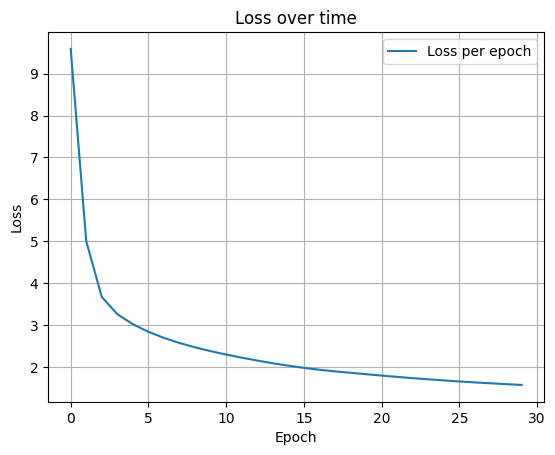

In [21]:
plt.plot([i for i in range(len(history))], history, label="Loss per epoch")
plt.title("Loss over time")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.legend()
plt.show()

In [28]:
input_test="bob likes cars"
output_test=model.inference(input_test)

print("INPUT:",input_test)
print("OUTPUT:",output_test)

INPUT: bob likes cars
OUTPUT:  bob likes cars <EOS>
